In [5]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [14]:
# data preprocessing

import pandas as pd

data = {
    'Name':['Pavan' , 'Kapil' , 'Lalit' , 'Ishan' , 'Om'],
    'Age':[25, None , 44 , 32 , None],
    'Salary':[50000, 60000 , 70000 , None , None]
}

df = pd.DataFrame(data)
df.head()

,Name,Age,Salary
0,Pavan,25.0,50000.0
1,Kapil,NaN,60000.0
2,Lalit,44.0,70000.0
3,Ishan,32.0,NaN
4,Om,NaN,NaN


In [15]:
# check null
print(df.isnull().sum())

Name      0
Age       2
Salary    2
dtype: int64


In [16]:
# check how much percent data is missing

print(df.isnull().mean()*100)

Name       0.0
Age       40.0
Salary    40.0
dtype: float64


In [17]:
# drop the col

df_frop=df.dropna()
print(df_frop)

    Name   Age   Salary
0  Pavan  25.0  50000.0
2  Lalit  44.0  70000.0


In [18]:
# fill the missing value with avg

df['Age'].fillna(df['Age'].mean(), inplace=True)
df['Salary'].fillna(df['Salary'].mean(), inplace=True)
print(df)

    Name        Age   Salary
0  Pavan  25.000000  50000.0
1  Kapil  33.666667  60000.0
2  Lalit  44.000000  70000.0
3  Ishan  32.000000  60000.0
4     Om  33.666667  60000.0


C:\Users\ce\AppData\Local\Temp\ipykernel_37380\2923572332.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)
C:\Users\ce\AppData\Local\Temp\ipykernel_37380\2923572332.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, 

In [19]:
# check how much percent data is missing

print(df.isnull().mean()*100)

Name      0.0
Age       0.0
Salary    0.0
dtype: float64


In [ ]:
# Lebel Encoding

# In machine learning, models work with numbers, not text.
# But often, our dataset has categorical values (like "Male", "Female", "Red", "Blue").
# Label Encoding converts these text labels into numeric codes.

# Gender:  Male, Female
# Male   → 1
# Female → 0

In [20]:
from sklearn.preprocessing import LabelEncoder

# Sample data
colors = ["Red", "Blue", "Green", "Blue", "Red"]

# Create encoder
encoder = LabelEncoder()

# Fit and transform
encoded_colors = encoder.fit_transform(colors)

# fit() → Learn from the data (find the rules, like min/max, mean, or encoding mapping).
# transform() → Apply those learned rules to actually change the data.
# fit_transform() → Does both steps together in one go.

print("Original:", colors)
print("Encoded :", encoded_colors)

Original: ['Red', 'Blue', 'Green', 'Blue', 'Red']
Encoded : [2 0 1 0 2]


In [21]:
# One hot Encoding

# convert categorical (text) data into numbers.

# ["Red", "Blue", "Green", "Blue"]

# | Color | Red | Blue | Green |
# | ----- | --- | ---- | ----- |
# | Red   | 1   | 0    | 0     |
# | Blue  | 0   | 1    | 0     |
# | Green | 0   | 0    | 1     |
# | Blue  | 0   | 1    | 0     |


In [23]:
import pandas as pd

# Sample data
data = {
    'Person': ['A', 'B', 'C', 'D'],
    'Fruit': ['Apple', 'Banana', 'Orange', 'Banana']
    }

df = pd.DataFrame(data)

# Apply One-Hot Encoding
encoded_df = pd.get_dummies(df, columns=['Fruit'])

print(encoded_df)

  Person  Fruit_Apple  Fruit_Banana  Fruit_Orange
0      A         True         False         False
1      B        False          True         False
2      C        False         False          True
3      D        False          True         False


In [24]:
# convert true false in binary form using pandas One-Hot Encoding + convert True/False → 1/0

encoded_df = pd.get_dummies(df, columns=['Fruit']).astype(int, errors='ignore')
print(encoded_df)

  Person  Fruit_Apple  Fruit_Banana  Fruit_Orange
0      A            1             0             0
1      B            0             1             0
2      C            0             0             1
3      D            0             1             0


In [25]:
# Feature scaling

# Feature Scaling = bringing all features to a similar scale.

# Imagine you’re comparing two students:

# Student	Marks (out of 100)	Pocket Money (₹ per month)
# A	80	5000
# B	90	7000

# If you use these features directly in ML:
# Marks are in the range of 0–100
# Money is in the range of 1000s

# The model may wrongly think money is more important just because the numbers are bigger.

# Feature Scaling puts both features into a similar range (e.g., 0–1).
# After scaling:
# Marks: 0.80, 0.90
# Money: 0.50, 0.70

# Now both are comparable .

# two types of feature scaling
# min max scaling
# StandardScaler / Z-Score Scaler

In [26]:
# StandardScaler

# It transforms your data so that:
# The mean =0
# The standard deviation = 1

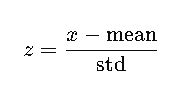

In [27]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Small dataset
data = {'Age': [10, 20, 30],
        'Salary': [1000, 5000, 10000]}

df = pd.DataFrame(data)
print("Original Data:\n", df)

# Perform Standard scaler
scaler = StandardScaler()
scaled = scaler.fit_transform(df)

scaled_df = pd.DataFrame(scaled, columns=['Age', 'Salary'])
print("\nAfter StandardScaler:\n", scaled_df.round(2))

Original Data:
    Age  Salary
0   10    1000
1   20    5000
2   30   10000

After StandardScaler:
     Age  Salary
0 -1.22   -1.18
1  0.00   -0.09
2  1.22    1.27


In [28]:
# min max scaler

# It rescales the data so that all values lie between 0 and 1.

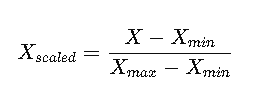

In [29]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# Sample data
data = {'Maths': [90, 60, 75],
        'Physics': [180, 120, 150]}

df = pd.DataFrame(data)
print("Original Data:\n", df)

# Apply Min-Max Scaling
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(scaled_data, columns=['Maths', 'Physics'])

print("\nScaled Data (0–1):\n", scaled_df)

Original Data:
    Maths  Physics
0     90      180
1     60      120
2     75      150

Scaled Data (0–1):
    Maths  Physics
0    1.0      1.0
1    0.0      0.0
2    0.5      0.5


In [30]:
# Splitting Data :

# In ML, we divide our dataset into two parts:
# Training set → used to teach the model.
# Testing set → used to check how well the model learned

# Example :
# Just like in school:
# Training = Studying from textbooks.
# Testing = Giving an exam with new questions.

# Suppose you have 100 emails labeled as Spam/Not Spam.
# You use 80 emails to train the model (learn).
# You keep 20 emails aside to test if the model predicts correctly.

In [31]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Sample dataset
data = {
    'Hours_Studied': [1,2,3,4,5,6,7,8,9,10],
    'Marks': [10,20,30,40,50,60,70,80,90,100]
}

df = pd.DataFrame(data)

scaler = StandardScaler()
standard_scaler = scaler.fit_transform(df)  # Fit + Transform on training data
print("Standard scaler output")
print(pd.DataFrame(standard_scaler.round(2), columns=['Hours_Studied', 'Marks']))


# Min max scaler
scaler = MinMaxScaler()
min_max_scaler = scaler.fit_transform(df)  # Fit + Transform on training data
print("\nMin-Max scaler output")
print(pd.DataFrame(min_max_scaler.round(2), columns=['Hours_Studied', 'Marks']))

print("\nTrain and Test dataset ")
X = df[['Hours_Studied']]   # Feature
y = df['Marks']

# Split data: 80% for training, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Data:\n", X_train, "\n")
print("Testing Data:\n", X_test)


Standard scaler output
   Hours_Studied  Marks
0          -1.57  -1.57
1          -1.22  -1.22
2          -0.87  -0.87
3          -0.52  -0.52
4          -0.17  -0.17
5           0.17   0.17
6           0.52   0.52
7           0.87   0.87
8           1.22   1.22
9           1.57   1.57

Min-Max scaler output
   Hours_Studied  Marks
0           0.00   0.00
1           0.11   0.11
2           0.22   0.22
3           0.33   0.33
4           0.44   0.44
5           0.56   0.56
6           0.67   0.67
7           0.78   0.78
8           0.89   0.89
9           1.00   1.00

Train and Test dataset 
Training Data:
    Hours_Studied
5              6
0              1
7              8
2              3
9             10
4              5
3              4
6              7 

Testing Data:
    Hours_Studied
8              9
1              2
